In [2]:
import pandas as pd
carac = pd.read_csv("../data/caract-2024.csv", sep=";", low_memory=False)
carac.head()

,Num_Acc,jour,mois,an,hrmn,lum,dep,com,agg,int,atm,col,adr,lat,long
0,202400000001,25,3,2024,07:40,2,70,70285,1,1,5,1,D438,"47,56277000","6,75832000"
1,202400000002,20,3,2024,15:05,1,21,21054,2,3,7,6,HOTEL DIEU (RUE DE L'),"47,02109000","4,83755000"
2,202400000003,22,3,2024,19:30,2,15,15012,1,1,1,6,Allée des Tilleuls,"44,90238400","2,49641800"
3,202400000004,24,3,2024,17:50,1,14,14118,2,3,7,3,128 Rue d'Authie,"49,19166000","-0,39851000"
4,202400000005,25,3,2024,19:35,5,13,13106,1,3,2,5,BEDOULE (CHEMIN DE LA),"43,39000000","5,35000000"


In [3]:
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns

carac     = pd.read_csv("../data/caract-2024.csv", sep=";", low_memory=False)
lieux     = pd.read_csv("../data/lieux-2024.csv", sep=";", low_memory=False)
usagers   = pd.read_csv("../data/usagers-2024.csv", sep=";", low_memory=False)
vehicules = pd.read_csv("../data/vehicules-2024.csv", sep=";", low_memory=False)

In [4]:
for nom, df in [("carac", carac), ("lieux", lieux), ("usagers", usagers), ("vehicules", vehicules)]:
    print(nom, df.shape)

carac (54402, 15)
lieux (70248, 18)
usagers (125187, 16)
vehicules (92678, 11)


In [5]:
print(carac.columns.tolist())
print(lieux.columns.tolist())
print(usagers.columns.tolist())
print(vehicules.columns.tolist())

['Num_Acc', 'jour', 'mois', 'an', 'hrmn', 'lum', 'dep', 'com', 'agg', 'int', 'atm', 'col', 'adr', 'lat', 'long']
['Num_Acc', 'catr', 'voie', 'v1', 'v2', 'circ', 'nbv', 'vosp', 'prof', 'pr', 'pr1', 'plan', 'lartpc', 'larrout', 'surf', 'infra', 'situ', 'vma']
['Num_Acc', 'id_usager', 'id_vehicule', 'num_veh', 'place', 'catu', 'grav', 'sexe', 'an_nais', 'trajet', 'secu1', 'secu2', 'secu3', 'locp', 'actp', 'etatp']
['Num_Acc', 'id_vehicule', 'num_veh', 'senc', 'catv', 'obs', 'obsm', 'choc', 'manv', 'motor', 'occutc']


In [6]:
print(carac.isna().sum())
print("Doublons :", carac.duplicated().sum())

Num_Acc       0
jour          0
mois          0
an            0
hrmn          0
lum           0
dep           0
com           0
agg           0
int           0
atm           0
col           0
adr        2310
lat           0
long          0
dtype: int64
Doublons : 0


In [7]:
carac.head()

,Num_Acc,jour,mois,an,hrmn,lum,dep,com,agg,int,atm,col,adr,lat,long
0,202400000001,25,3,2024,07:40,2,70,70285,1,1,5,1,D438,"47,56277000","6,75832000"
1,202400000002,20,3,2024,15:05,1,21,21054,2,3,7,6,HOTEL DIEU (RUE DE L'),"47,02109000","4,83755000"
2,202400000003,22,3,2024,19:30,2,15,15012,1,1,1,6,Allée des Tilleuls,"44,90238400","2,49641800"
3,202400000004,24,3,2024,17:50,1,14,14118,2,3,7,3,128 Rue d'Authie,"49,19166000","-0,39851000"
4,202400000005,25,3,2024,19:35,5,13,13106,1,3,2,5,BEDOULE (CHEMIN DE LA),"43,39000000","5,35000000"


In [8]:
carac["date"] = pd.to_datetime(dict(year=carac["an"], month=carac["mois"], day=carac["jour"]))
carac["jour_semaine"] = carac["date"].dt.day_name()
carac["heure"] = carac["hrmn"].astype(str).str[:2].astype(int)

carac[["date", "jour_semaine", "hrmn", "heure"]].head()

,date,jour_semaine,hrmn,heure
0,2024-03-25,Monday,07:40,7
1,2024-03-20,Wednesday,15:05,15
2,2024-03-22,Friday,19:30,19
3,2024-03-24,Sunday,17:50,17
4,2024-03-25,Monday,19:35,19


In [9]:
print("Avant :", usagers.shape)
usagers["age"] = 2023 - usagers["an_nais"]
usagers = usagers[(usagers["age"] >= 0) & (usagers["age"] <= 100)]
print("Après :", usagers.shape)

Avant : (125187, 16)
Après : (122429, 17)


In [10]:
gravite = {1: "Indemne", 2: "Tué", 3: "Blessé hospitalisé", 4: "Blessé léger"}
lumiere = {1: "Plein jour", 2: "Aube/crépuscule", 3: "Nuit sans éclairage",
           4: "Nuit éclairage éteint", 5: "Nuit éclairage allumé"}
meteo = {1: "Normale", 2: "Pluie légère", 3: "Pluie forte", 4: "Neige/grêle",
         5: "Brouillard/fumée", 6: "Vent fort/tempête", 7: "Éblouissant",
         8: "Couvert", 9: "Autre"}
route = {1: "Autoroute", 2: "Route nationale", 3: "Route départementale",
         4: "Voie communale", 5: "Hors réseau public", 6: "Parking",
         7: "Métropole urbaine", 9: "Autre"}

usagers["gravite"]    = usagers["grav"].map(gravite)
carac["luminosite"]   = carac["lum"].map(lumiere)
carac["meteo"]        = carac["atm"].map(meteo)
lieux["type_route"]   = lieux["catr"].map(route)

In [11]:
for nom, df in [("carac", carac), ("lieux", lieux), ("usagers", usagers), ("vehicules", vehicules)]:
    print(nom, "doublons :", df.duplicated().sum())

carac doublons : 0
lieux doublons : 2
usagers doublons : 0
vehicules doublons : 0


In [12]:
print(usagers["gravite"].value_counts(dropna=False))
print(carac["luminosite"].value_counts(dropna=False))

gravite
Indemne               50278
Blessé léger          49612
Blessé hospitalisé    19111
Tué                    3428
Name: count, dtype: int64
luminosite
Plein jour               35580
Nuit éclairage allumé     8499
Nuit sans éclairage       6101
Aube/crépuscule           3599
Nuit éclairage éteint      623
Name: count, dtype: int64


In [14]:
usagers = pd.read_csv("../data/usagers-2024.csv", sep=";", low_memory=False)

annee = int(carac["an"].iloc[0])
print("Année des données :", annee)

usagers["age"] = annee - usagers["an_nais"]
print("Avant :", usagers.shape)
usagers = usagers[(usagers["age"] >= 0) & (usagers["age"] <= 100)]
print("Après :", usagers.shape)

usagers["gravite"] = usagers["grav"].map(gravite)

Année des données : 2024
Avant : (125187, 17)
Après : (122602, 17)


In [15]:
conn = sqlite3.connect("../data/accidents.db")

carac.to_sql("caracteristiques", conn, if_exists="replace", index=False)
lieux.to_sql("lieux", conn, if_exists="replace", index=False)
usagers.to_sql("usagers", conn, if_exists="replace", index=False)
vehicules.to_sql("vehicules", conn, if_exists="replace", index=False)

92678

In [16]:
def sql(requete):
    return pd.read_sql_query(requete, conn)

sql("SELECT COUNT(*) AS nb_accidents FROM caracteristiques")

,nb_accidents
0,54402


In [17]:
   sql("""
   SELECT heure, COUNT(*) AS nb_accidents
   FROM caracteristiques
   GROUP BY heure
   ORDER BY heure
   """)

,heure,nb_accidents
0,0,1168
1,1,955
2,2,807
3,3,602
4,4,630
5,5,886
6,6,1218
7,7,2442
8,8,3161
9,9,2673


In [18]:
sql("""
SELECT mois, COUNT(*) AS nb_accidents
FROM caracteristiques
GROUP BY mois
ORDER BY mois
""")

,mois,nb_accidents
0,1,4069
1,2,3792
2,3,4370
3,4,4586
4,5,4517
5,6,5135
6,7,5209
7,8,4450
8,9,4620
9,10,4803


In [19]:
sql("""
SELECT gravite,
       COUNT(*) AS nb_usagers,
       ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM usagers), 1) AS pourcentage
FROM usagers
GROUP BY gravite
ORDER BY nb_usagers DESC
""")

,gravite,nb_usagers,pourcentage
0,Indemne,50345,41.1
1,Blessé léger,49701,40.5
2,Blessé hospitalisé,19125,15.6
3,Tué,3431,2.8


In [20]:
sql("""
SELECT c.luminosite,
       COUNT(*) AS nb_usagers,
       SUM(u.grav = 2) AS nb_tues,
       ROUND(100.0 * SUM(u.grav = 2) / COUNT(*), 2) AS taux_tues_pct
FROM caracteristiques c
JOIN usagers u ON c.Num_Acc = u.Num_Acc
WHERE c.luminosite IS NOT NULL
GROUP BY c.luminosite
ORDER BY taux_tues_pct DESC
""")

,luminosite,nb_usagers,nb_tues,taux_tues_pct
0,Nuit sans éclairage,14102,883,6.26
1,Nuit éclairage éteint,1383,63,4.56
2,Aube/crépuscule,7993,243,3.04
3,Plein jour,80366,1933,2.41
4,Nuit éclairage allumé,18758,309,1.65


In [21]:
sql("""
SELECT l.type_route,
       COUNT(*) AS nb_usagers,
       SUM(u.grav = 2) AS nb_tues,
       ROUND(100.0 * SUM(u.grav = 2) / COUNT(*), 2) AS taux_tues_pct
FROM lieux l
JOIN usagers u ON l.Num_Acc = u.Num_Acc
WHERE l.type_route IS NOT NULL
GROUP BY l.type_route
ORDER BY taux_tues_pct DESC
""")

,type_route,nb_usagers,nb_tues,taux_tues_pct
0,Autre,474,24,5.06
1,Hors réseau public,125,5,4.00
2,Route départementale,60167,2364,3.93
3,Route nationale,10067,327,3.25
4,Parking,897,25,2.79
5,Métropole urbaine,4600,108,2.35
6,Autoroute,14327,252,1.76
7,Voie communale,68423,846,1.24


In [22]:
sql("""
SELECT dep, COUNT(*) AS nb_accidents
FROM caracteristiques
GROUP BY dep
HAVING COUNT(*) > 500
ORDER BY nb_accidents DESC
LIMIT 10
""")

,dep,nb_accidents
0,75,4191
1,93,2640
2,92,2485
3,13,2120
4,94,1963
5,69,1627
6,91,1348
7,33,1202
8,77,1068
9,59,1023


In [23]:
sql("""
SELECT c.meteo,
       COUNT(*) AS nb_usagers,
       ROUND(100.0 * SUM(u.grav = 2) / COUNT(*), 2) AS taux_tues_pct
FROM caracteristiques c
JOIN usagers u ON c.Num_Acc = u.Num_Acc
WHERE c.meteo IS NOT NULL
GROUP BY c.meteo
ORDER BY taux_tues_pct DESC
""")

,meteo,nb_usagers,taux_tues_pct
0,Vent fort/tempête,354,7.34
1,Brouillard/fumée,1291,6.58
2,Autre,524,4.20
3,Pluie forte,3357,3.40
4,Éblouissant,1812,3.37
5,Normale,94215,2.79
6,Neige/grêle,595,2.69
7,Couvert,5300,2.55
8,Pluie légère,15154,2.28


In [24]:
sns.set_theme(style="whitegrid")
COULEUR = "#4C72B0"

def graphique(df, x, y, titre, xlabel, ylabel, fichier, horizontal=False):
    plt.figure(figsize=(10, 5))
    if horizontal:
        sns.barplot(data=df, x=x, y=y, color=COULEUR, orient="h")
    else:
        sns.barplot(data=df, x=x, y=y, color=COULEUR)
    plt.title(titre)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.tight_layout()
    plt.savefig(f"../figures/{fichier}", dpi=150)
    plt.show()

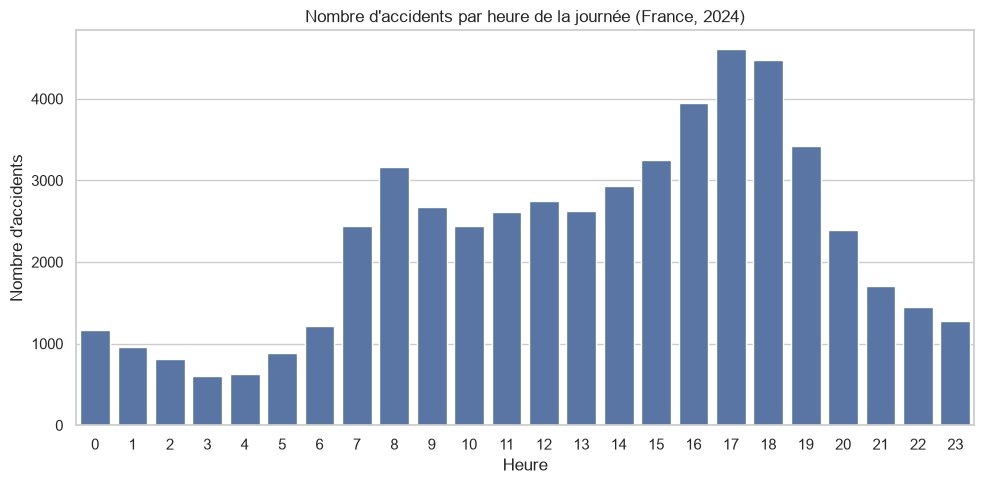

In [25]:
df = sql("""
SELECT heure, COUNT(*) AS nb_accidents
FROM caracteristiques
GROUP BY heure ORDER BY heure
""")
graphique(df, "heure", "nb_accidents",
          "Nombre d'accidents par heure de la journée (France, 2024)",
          "Heure", "Nombre d'accidents", "accidents_par_heure.png")

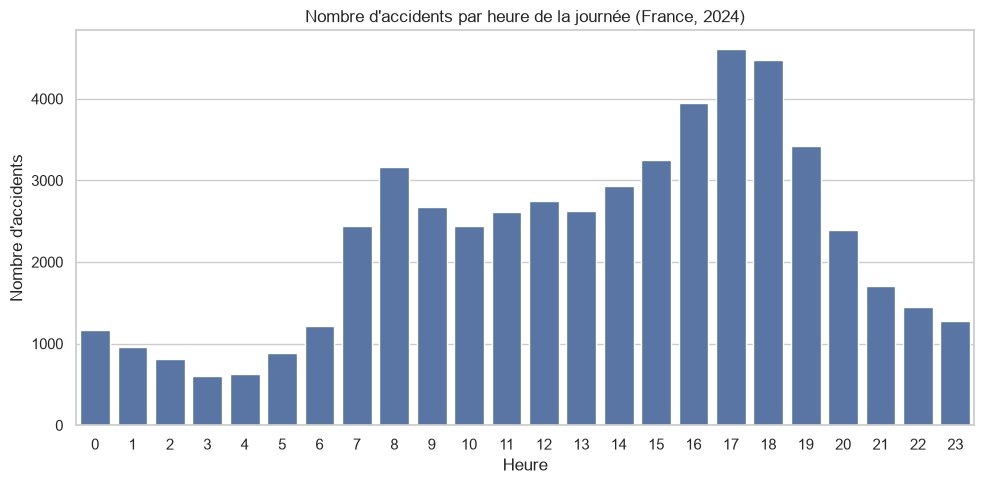

In [26]:
df = sql("""
SELECT heure, COUNT(*) AS nb_accidents
FROM caracteristiques
GROUP BY heure ORDER BY heure
""")
graphique(df, "heure", "nb_accidents",
          "Nombre d'accidents par heure de la journée (France, 2024)",
          "Heure", "Nombre d'accidents", "accidents_par_heure.png")

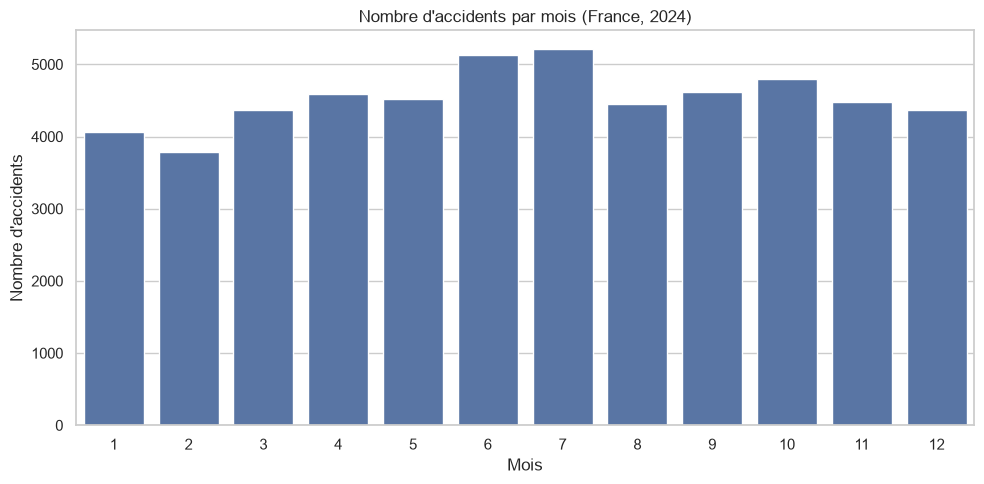

In [27]:
df = sql("""
SELECT mois, COUNT(*) AS nb_accidents
FROM caracteristiques
GROUP BY mois ORDER BY mois
""")
graphique(df, "mois", "nb_accidents",
          "Nombre d'accidents par mois (France, 2024)",
          "Mois", "Nombre d'accidents", "accidents_par_mois.png")

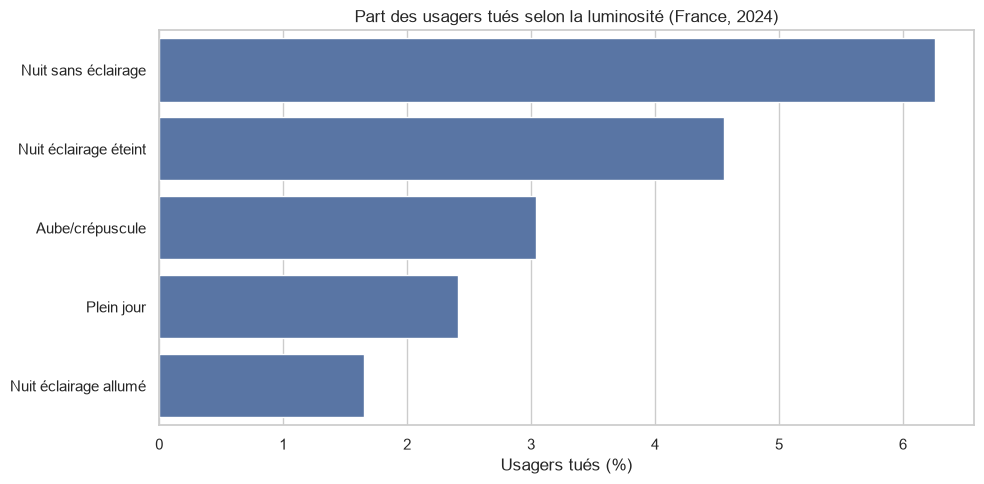

In [28]:
df = sql("""
SELECT c.luminosite,
       ROUND(100.0 * SUM(u.grav = 2) / COUNT(*), 2) AS taux_tues_pct
FROM caracteristiques c
JOIN usagers u ON c.Num_Acc = u.Num_Acc
WHERE c.luminosite IS NOT NULL
GROUP BY c.luminosite ORDER BY taux_tues_pct DESC
""")
graphique(df, "taux_tues_pct", "luminosite",
          "Part des usagers tués selon la luminosité (France, 2024)",
          "Usagers tués (%)", "", "tues_par_luminosite.png", horizontal=True)

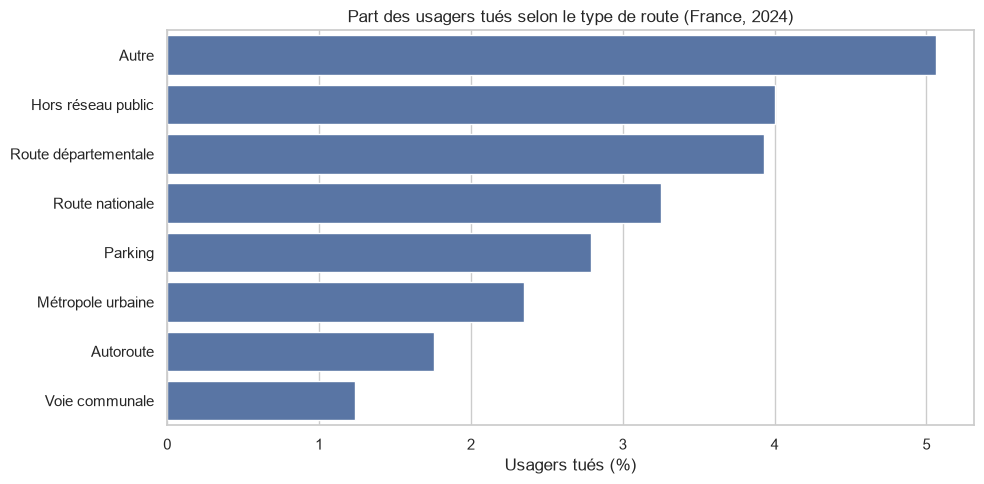

In [29]:
df = sql("""
SELECT l.type_route,
       ROUND(100.0 * SUM(u.grav = 2) / COUNT(*), 2) AS taux_tues_pct
FROM lieux l
JOIN usagers u ON l.Num_Acc = u.Num_Acc
WHERE l.type_route IS NOT NULL
GROUP BY l.type_route ORDER BY taux_tues_pct DESC
""")
graphique(df, "taux_tues_pct", "type_route",
          "Part des usagers tués selon le type de route (France, 2024)",
          "Usagers tués (%)", "", "tues_par_type_route.png", horizontal=True)

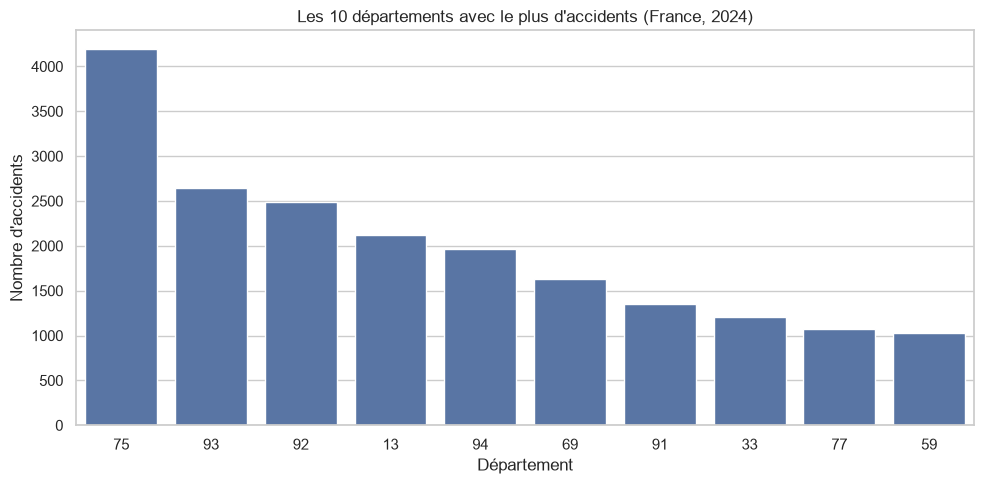

In [30]:
df = sql("""
SELECT dep, COUNT(*) AS nb_accidents
FROM caracteristiques
GROUP BY dep ORDER BY nb_accidents DESC LIMIT 10
""")
graphique(df, "dep", "nb_accidents",
          "Les 10 départements avec le plus d'accidents (France, 2024)",
          "Département", "Nombre d'accidents", "top10_departements.png")

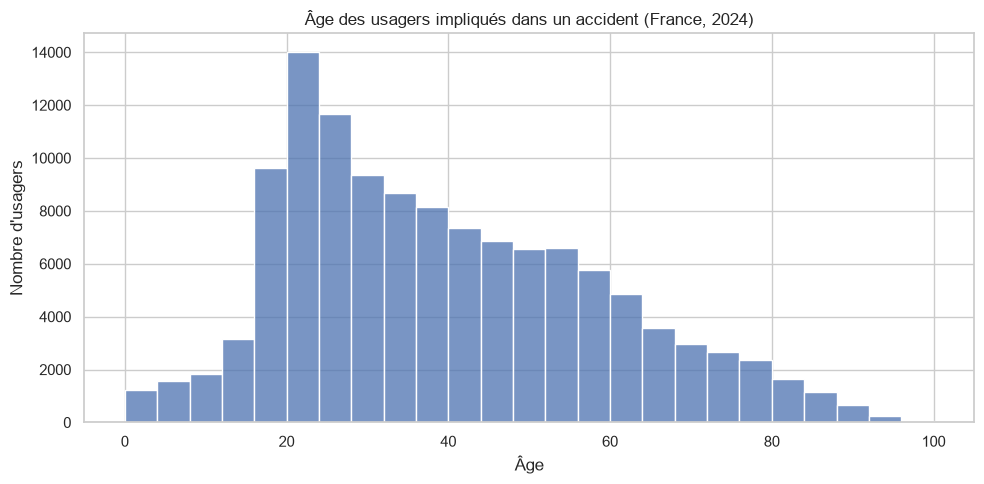

In [31]:
plt.figure(figsize=(10, 5))
sns.histplot(data=usagers, x="age", bins=25, color=COULEUR)
plt.title("Âge des usagers impliqués dans un accident (France, 2024)")
plt.xlabel("Âge"); plt.ylabel("Nombre d'usagers")
plt.tight_layout()
plt.savefig("../figures/age_usagers.png", dpi=150)
plt.show()

In [32]:
print("Accidents :", sql("SELECT COUNT(*) AS n FROM caracteristiques")["n"][0])
print("Usagers impliqués :", len(usagers))
print("Usagers tués :", (usagers["grav"] == 2).sum())

print(sql("""
SELECT ROUND(100.0 * SUM(heure BETWEEN 17 AND 18) / COUNT(*), 1) AS pct_17h_19h,
       ROUND(100.0 * SUM(luminosite = 'Plein jour') / COUNT(*), 1) AS pct_plein_jour
FROM caracteristiques
"""))

print(sql("SELECT heure, COUNT(*) AS n FROM caracteristiques GROUP BY heure ORDER BY n DESC LIMIT 3"))
print(sql("SELECT mois, COUNT(*) AS n FROM caracteristiques GROUP BY mois ORDER BY n DESC LIMIT 3"))

Accidents : 54402
Usagers impliqués : 122602
Usagers tués : 3431
   pct_17h_19h  pct_plein_jour
0         16.7            65.4
   heure     n
0     17  4607
1     18  4470
2     16  3944
   mois     n
0     7  5209
1     6  5135
2    10  4803
